# Cookie Cats — аудит данных и EDA

Проверяем качество [данных эксперимента](../data/README.md) и описываем удержание и игровую активность по группам. Метрики заданы в [дизайне эксперимента](../docs/experiment_design.md).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import chisquare

In [2]:
data_path = Path('data/raw/cookie_cats.csv')
if not data_path.is_file():
    data_path = Path('..') / data_path

df = pd.read_csv(data_path)
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## Аудит данных

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB


In [4]:
df.isna().sum()

userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

In [5]:
expected_columns = {'userid', 'version', 'sum_gamerounds', 'retention_1', 'retention_7'}
assert set(df.columns) == expected_columns, 'Схема CSV отличается от ожидаемой'
assert not df.isna().any().any(), 'В данных есть пропуски'
assert df['userid'].is_unique, 'Есть повторяющиеся userid'
assert set(df['version']) == {'gate_30', 'gate_40'}, 'Неверный состав групп'
assert df[['retention_1', 'retention_7']].isin([True, False]).all().all(), (
    'Удержание должно быть бинарным'
)
assert df['sum_gamerounds'].ge(0).all(), 'Есть отрицательное число раундов'

group_sizes = df['version'].value_counts().sort_index()
group_sizes.rename('Игроков').to_frame()

,Игроков
version,
gate_30,44700
gate_40,45489


В выгрузке 90 189 строк и 90 189 уникальных игроков. Пропусков нет. Присутствуют обе ожидаемые группы, признаки удержания бинарные, отрицательных значений числа раундов нет.

## SRM

Проверяем согласие наблюдаемых размеров групп с распределением 50/50. Это допущение о плане назначения игроков.

In [6]:
expected_group_size = group_sizes.sum() / 2
srm = chisquare(f_obs=group_sizes, f_exp=expected_group_size)

print(f'Ожидаемое число игроков в каждой группе: {expected_group_size:.1f}')
print(f'Статистика χ²: {srm.statistic:.4f}, p-value: {srm.pvalue:.4f}')

Ожидаемое число игроков в каждой группе: 45094.5
Статистика χ²: 6.9024, p-value: 0.0086


При случайном распределении 50/50 перекос такой величины или сильнее возникал бы примерно в 0,86% повторов. Исходная пропорция назначения и причина перекоса остаются неизвестными. Это ограничивает интерпретацию различий между группами.

## Удержание

In [7]:
retention_by_version = df.groupby('version').agg(
    players=('userid', 'size'),
    d1=('retention_1', 'mean'),
    d7=('retention_7', 'mean'),
)

retention_by_version.assign(
    d1=retention_by_version['d1'].map('{:.2%}'.format),
    d7=retention_by_version['d7'].map('{:.2%}'.format),
)

,players,d1,d7
version,,,
gate_30,44700,44.82%,19.02%
gate_40,45489,44.23%,18.20%


В `gate_40` наблюдаемое удержание ниже на **0,59 п.п. по D1** и **0,82 п.п. по D7**. Статистическую неопределённость оценки D7 разберём на следующем этапе.

## Игровая активность

In [8]:
df['sum_gamerounds'].describe()

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

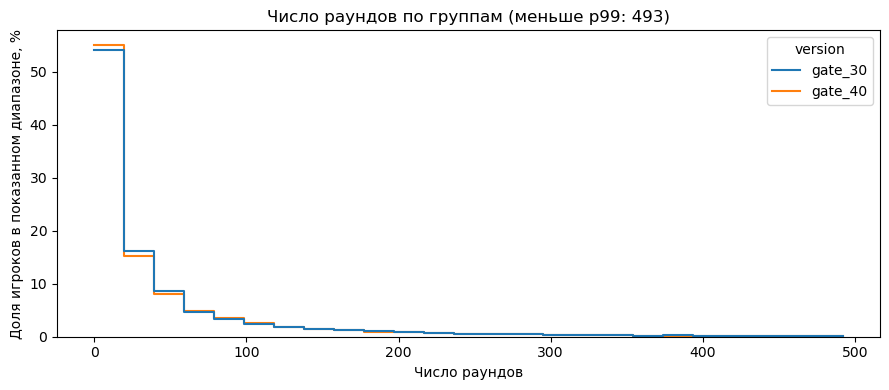

In [9]:
rounds_p99 = df['sum_gamerounds'].quantile(0.99)
players_below_rounds_p99 = df.loc[df['sum_gamerounds'] < rounds_p99]

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(
    data=players_below_rounds_p99,
    x='sum_gamerounds',
    hue='version',
    element='step',
    fill=False,
    stat='percent',
    common_norm=False,
    bins=25,
    ax=ax,
)
ax.set(
    title=f'Число раундов по группам (меньше p99: {rounds_p99:g})',
    xlabel='Число раундов',
    ylabel='Доля игроков в показанном диапазоне, %',
)
fig.tight_layout()
plt.show()

На графике показан диапазон ниже общего p99. Для расчёта долей в таблице используем всех игроков каждой группы.

In [10]:
activity_by_version = (
    df.assign(
        zero_rounds=df['sum_gamerounds'].eq(0),
        at_or_above_p99=df['sum_gamerounds'].ge(rounds_p99),
    )
    .groupby('version')
    .agg(
        share_zero_rounds=('zero_rounds', 'mean'),
        share_at_or_above_p99=('at_or_above_p99', 'mean'),
    )
)

activity_by_version.assign(
    share_zero_rounds=activity_by_version['share_zero_rounds'].map('{:.2%}'.format),
    share_at_or_above_p99=activity_by_version['share_at_or_above_p99'].map('{:.2%}'.format),
).rename(columns={
    'share_zero_rounds': '0 раундов',
    'share_at_or_above_p99': f'Не меньше {rounds_p99:g} раундов',
})

,0 раундов,Не меньше 493 раундов
version,,
gate_30,4.33%,1.01%
gate_40,4.52%,1.00%


Всего **3 994 игрока** сыграли 0 раундов. У распределения длинный правый хвост: 99-й перцентиль — **493**, максимум — **49 854** раунда. Доли игроков на уровне p99 и выше близки в обеих группах.

Число раундов измеряется после назначения варианта. Сравнение активности описательное, а в основной анализ D7 игроки входят по назначенной группе независимо от числа раундов.